# Decision trees on geographic fold 3

This notebook compares five sets of catalog and waveform features for classifying earthquakes and explosions in the Pacific Northwest.

To run the analysis, place this notebook and `pnw_training_corrected.csv` in the same folder, then run the cells from top to bottom.


## 1. Data and geographic split

The catalog labels earthquakes as `0` and explosions as `1`. We train on folds 1, 2, 4 and 5, then test on fold 3. Fold 3 is not used to fit the models or choose their settings or cutoff.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score,
    f1_score, roc_auc_score, brier_score_loss, confusion_matrix,
)

DATA_PATH = Path("pnw_training_corrected.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Put pnw_training_corrected.csv beside this notebook and run from that folder.")

df = pd.read_csv(DATA_PATH)
assert df.shape == (38579, 22), "Expected the corrected PNW dataset."
assert df["event_id"].is_unique
assert set(df["geographic_fold"]) == {1, 2, 3, 4, 5}

test = df["geographic_fold"] == 3
train = ~test
y_train = df.loc[train, "label"]
y_test = df.loc[test, "label"]
assert set(y_train) == {0, 1} and set(y_test) == {0, 1}


In [2]:
PAPER = "#FAF8F3"
INK = "#29383B"
MUTED = "#687471"
RULE = "#D9DED6"
SAGE = "#4F7569"
CLAY = "#A5664E"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "figure.facecolor": PAPER, "axes.facecolor": PAPER,
    "savefig.facecolor": PAPER, "text.color": INK,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": INK,
    "axes.edgecolor": RULE, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "normal",
    "figure.dpi": 120, "savefig.dpi": 200,
})


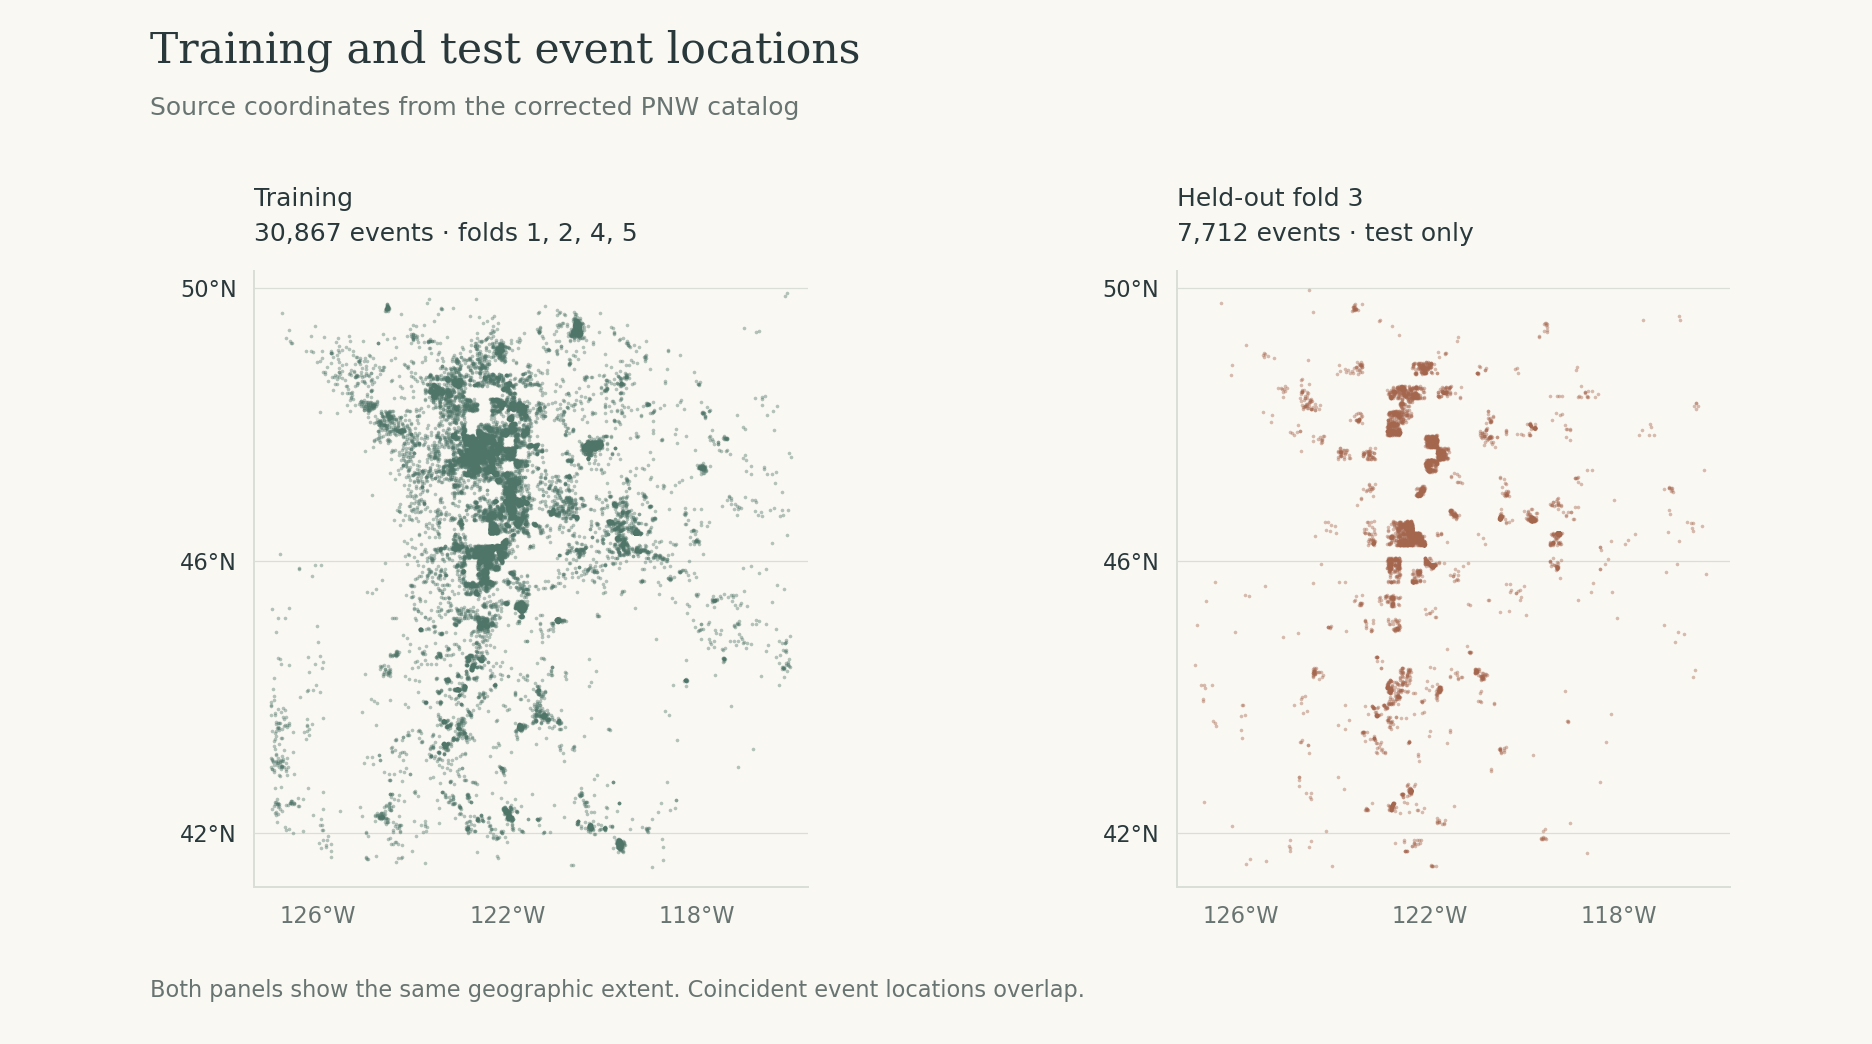

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 5.8))
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.15, top=0.74, wspace=0.21)
fig.text(0.08, 0.94, "Training and test event locations", 
         family="DejaVu Serif", fontsize=17)
fig.text(0.08, 0.89, "Source coordinates from the corrected PNW catalog", color=MUTED)

views = [
    (train, "Training", "30,867 events · folds 1, 2, 4, 5", SAGE),
    (test, "Held-out fold 3", "7,712 events · test only", CLAY),
]
for ax, (mask, title, subtitle, color) in zip(axes, views):
    ax.scatter(df.loc[mask, "source_longitude_deg"],
               df.loc[mask, "source_latitude_deg"],
               s=2.1, color=color, alpha=0.42, linewidths=0)
    ax.set_xlim(-127.35, -115.65)
    ax.set_ylim(41.2, 50.25)
    ax.set_aspect(1 / np.cos(np.deg2rad(46)))
    ax.set_xticks([-126, -122, -118])
    ax.set_yticks([42, 46, 50])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{abs(x):.0f}°W"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{y:.0f}°N"))
    ax.tick_params(length=0, pad=7, labelsize=9)
    ax.grid(axis="y", color=RULE, linewidth=0.5)
    ax.set_axisbelow(True)
    ax.set_title(title + "\n" + subtitle, loc="left", fontsize=10, pad=12, linespacing=1.6)

fig.text(0.08, 0.045, "Both panels show the same geographic extent. Coincident event locations overlap.",
         fontsize=9, color=MUTED)
plt.show()


The maps’ east–west scale is adjusted for latitude 46°N.

Training and test events come from separate spatial groups, but no minimum distance is required between those groups. A training event can therefore be close to a test event.


## 2. Feature sets and model fitting

Catalog inputs include location, magnitude, time of day and whether the event occurred on a weekend. Waveform inputs describe signal amplitude, frequency content, component ratios and envelope shape.

Catalog depth is the recorded depth of an event. Tree depth limits the number of decision steps in the model. Only the columns listed below are inputs; event IDs, labels, fold assignments and station counts are excluded.


In [4]:
CATALOG = [
    "source_latitude_deg",
    "source_longitude_deg",
    "preferred_source_magnitude",
    "local_hour_sin",
    "local_hour_cos",
    "weekend",
]

WAVEFORM = [
    "cb_crest_factor",
    "cb_spectral_entropy",
    "nb_log10_pz_sh_rms_ratio_4_8hz",
    "nb_log10_sh_sz_rms_ratio_4_8hz",
    "nb_envelope_rise_10_90_s_2_10hz",
    "nb_envelope_excess_kurtosis_2_10hz",
    "nb_log10_psd_power_1_5_over_5_15hz",
]

DEPTH = ["source_depth_km"]
FEATURE_SETS = {
    "Catalog": CATALOG,
    "Catalog + depth": CATALOG + DEPTH,
    "Catalog + waveform": CATALOG + WAVEFORM,
    "Catalog + waveform + depth": CATALOG + WAVEFORM + DEPTH,
    "Waveform only": WAVEFORM,
}

assert np.isfinite(df[CATALOG + WAVEFORM + DEPTH].to_numpy()).all()


We keep the teaching baseline's provisional settings and cutoff. We do not balance or resample the data, or tune the models on fold 3.

A tree divides the training events into groups called leaves. A test event receives an explosion score equal to the fraction of catalog explosions in the training leaf it reaches. A score of 0.5 or more flags an explosion. We have not checked whether these scores match explosion frequencies on independent data.


In [5]:
MAX_DEPTH = 3
RANDOM_STATE = 42
THRESHOLD = 0.5

result_rows = []

for name, columns in FEATURE_SETS.items():
    tree = DecisionTreeClassifier(
        max_depth=MAX_DEPTH,
        random_state=RANDOM_STATE,
        criterion="gini",
        class_weight=None,
    )
    tree.fit(df.loc[train, columns], y_train)

    positive_column = list(tree.classes_).index(1)
    scores = tree.predict_proba(df.loc[test, columns])[:, positive_column]
    predicted = (scores >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()

    result_rows.append({
        "model": name,
        "n_features": len(columns),
        "average_precision": average_precision_score(y_test, scores),
        "precision": precision_score(y_test, predicted, zero_division=0),
        "recall": recall_score(y_test, predicted, zero_division=0),
        "f1": f1_score(y_test, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y_test, scores),
        "brier_score": brier_score_loss(y_test, scores),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    })

results = pd.DataFrame(result_rows)


## 3. Average precision

Average precision (AP) summarizes the tradeoff between detecting explosions and avoiding false flags as the score cutoff changes. Higher AP is better. We calculate average precision using scikit-learn.


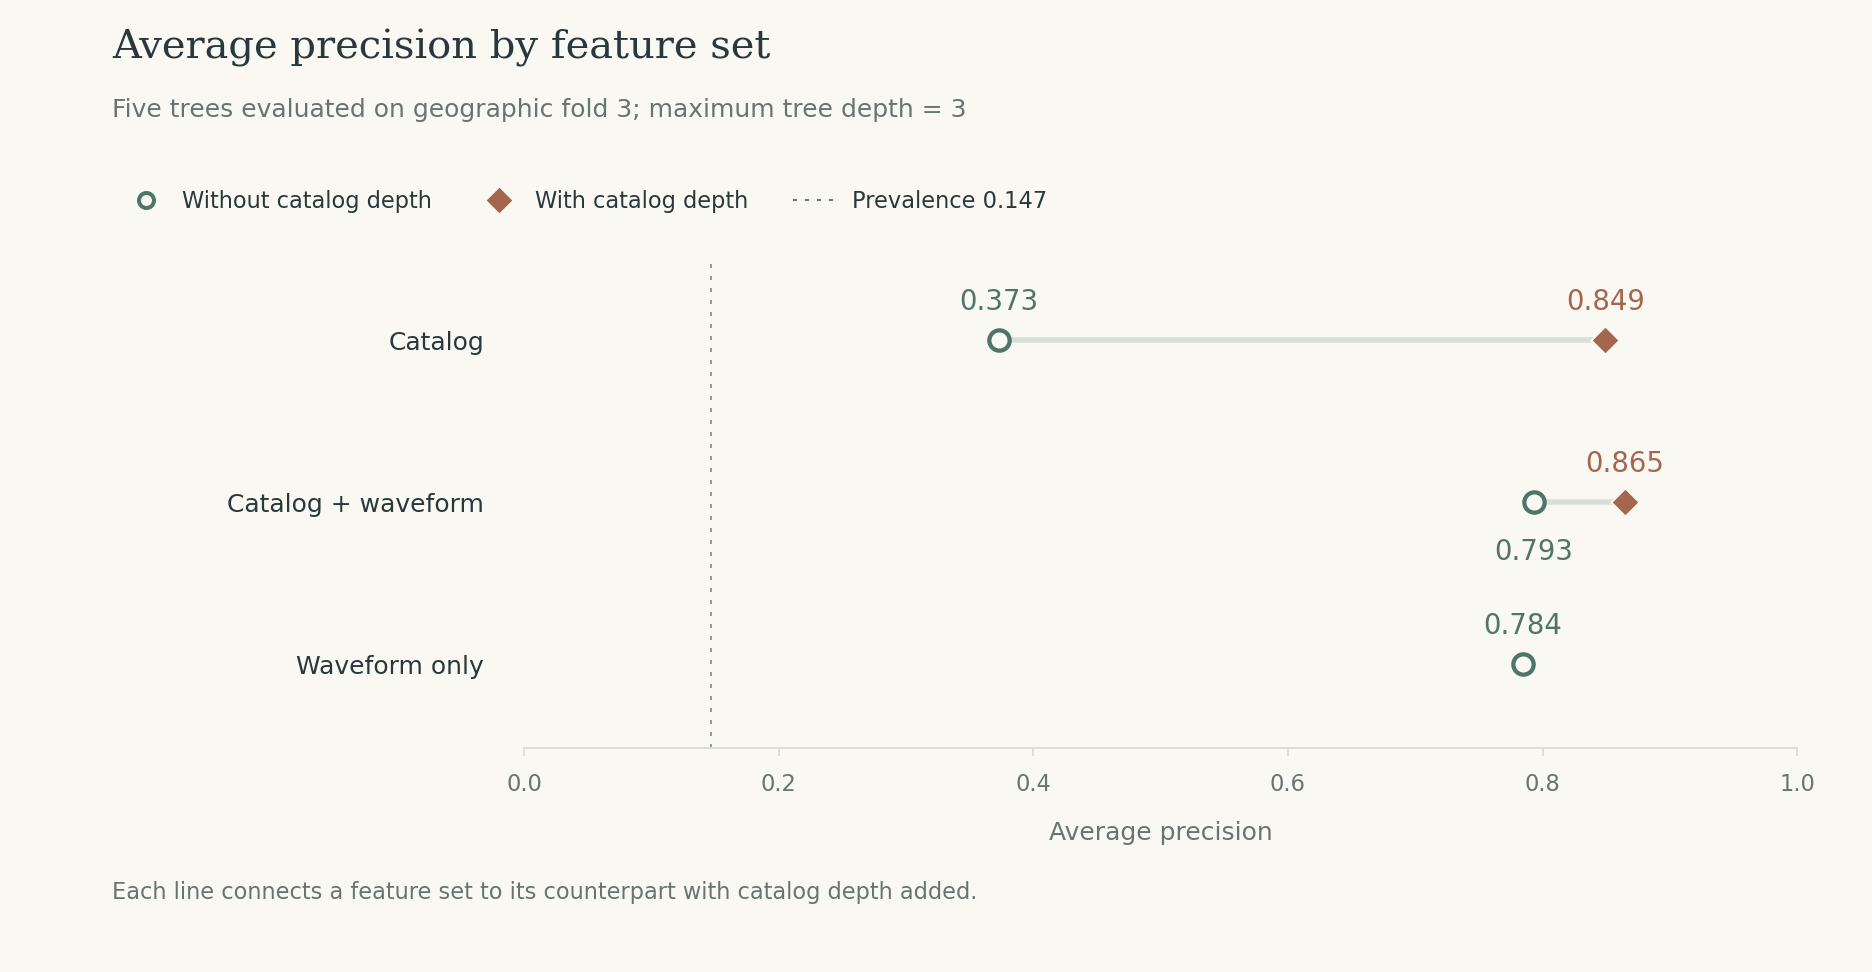

In [6]:
by_model = results.set_index("model")
prevalence = y_test.mean()

fig, ax = plt.subplots(figsize=(10.4, 5.4))
fig.subplots_adjust(left=0.28, right=0.96, bottom=0.23, top=0.73)
fig.text(0.06, 0.94, "Average precision by feature set",
         family="DejaVu Serif", fontsize=16)
fig.text(0.06, 0.88, "Five trees evaluated on geographic fold 3; maximum tree depth = 3", color=MUTED)

pairs = [
    (2, "Catalog", "Catalog + depth"),
    (1, "Catalog + waveform", "Catalog + waveform + depth"),
    (0, "Waveform only", None),
]
for y, without, with_depth in pairs:
    a = by_model.loc[without, "average_precision"]
    if with_depth is not None:
        b = by_model.loc[with_depth, "average_precision"]
        ax.plot([a, b], [y, y], color=RULE, linewidth=2.2, zorder=1)
        ax.scatter(b, y, s=64, marker="D", color=CLAY, edgecolor=PAPER, linewidth=0.8, zorder=3)
        ax.annotate(f"{b:.3f}", (b, y), xytext=(0, 12), textcoords="offset points",
                    ha="center", color=CLAY, fontsize=11)
    ax.scatter(a, y, s=66, marker="o", facecolor=PAPER, edgecolor=SAGE, linewidth=1.7, zorder=3)
    offset = -23 if without == "Catalog + waveform" else 12
    ax.annotate(f"{a:.3f}", (a, y), xytext=(0, offset), textcoords="offset points",
                ha="center", color=SAGE, fontsize=11)

ax.set_xlim(0, 1)
ax.set_ylim(-0.52, 2.48)
ax.set_yticks([2, 1, 0], ["Catalog", "Catalog + waveform", "Waveform only"])
ax.tick_params(axis="y", length=0, pad=16, labelsize=10)
ax.tick_params(axis="x", length=3, color=RULE, pad=7, labelsize=9)
ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.set_xlabel("Average precision", labelpad=10, fontsize=10)
ax.spines["left"].set_visible(False)
ax.axvline(prevalence, color=MUTED, linewidth=0.8, linestyle=(0, (2, 4)), alpha=0.7)

legend = [
    Line2D([0], [0], marker="o", linestyle="", markerfacecolor=PAPER,
           markeredgecolor=SAGE, markeredgewidth=1.6, label="Without catalog depth"),
    Line2D([0], [0], marker="D", linestyle="", color=CLAY, label="With catalog depth"),
    Line2D([0], [0], color=MUTED, linewidth=0.8, linestyle=(0, (2, 4)), label=f"Prevalence {prevalence:.3f}"),
]
fig.legend(handles=legend, loc="upper left", bbox_to_anchor=(0.055, 0.825),
           ncol=3, frameon=False, fontsize=9, handletextpad=0.6, columnspacing=2)
fig.text(0.06, 0.075, "Each line connects a feature set to its counterpart with catalog depth added.",
         fontsize=9, color=MUTED)
plt.show()


Adding waveform features raises Catalog AP from **0.373 to 0.793**. Adding depth also improves AP, with a larger gain for Catalog than for Catalog + waveform on this fold.

Catalog depth may reflect an analyst's earlier judgment about whether an event was an explosion. If that judgment influenced the recorded depth, the model could reuse it through the depth feature. This comparison cannot tell how much of the improvement comes from physical depth differences versus cataloging decisions.


## 4. Predictions at cutoff 0.5

False positives are catalog earthquakes flagged as explosions. The plot places these on the left and correctly detected explosions on the right, using the same event-count scale for both.


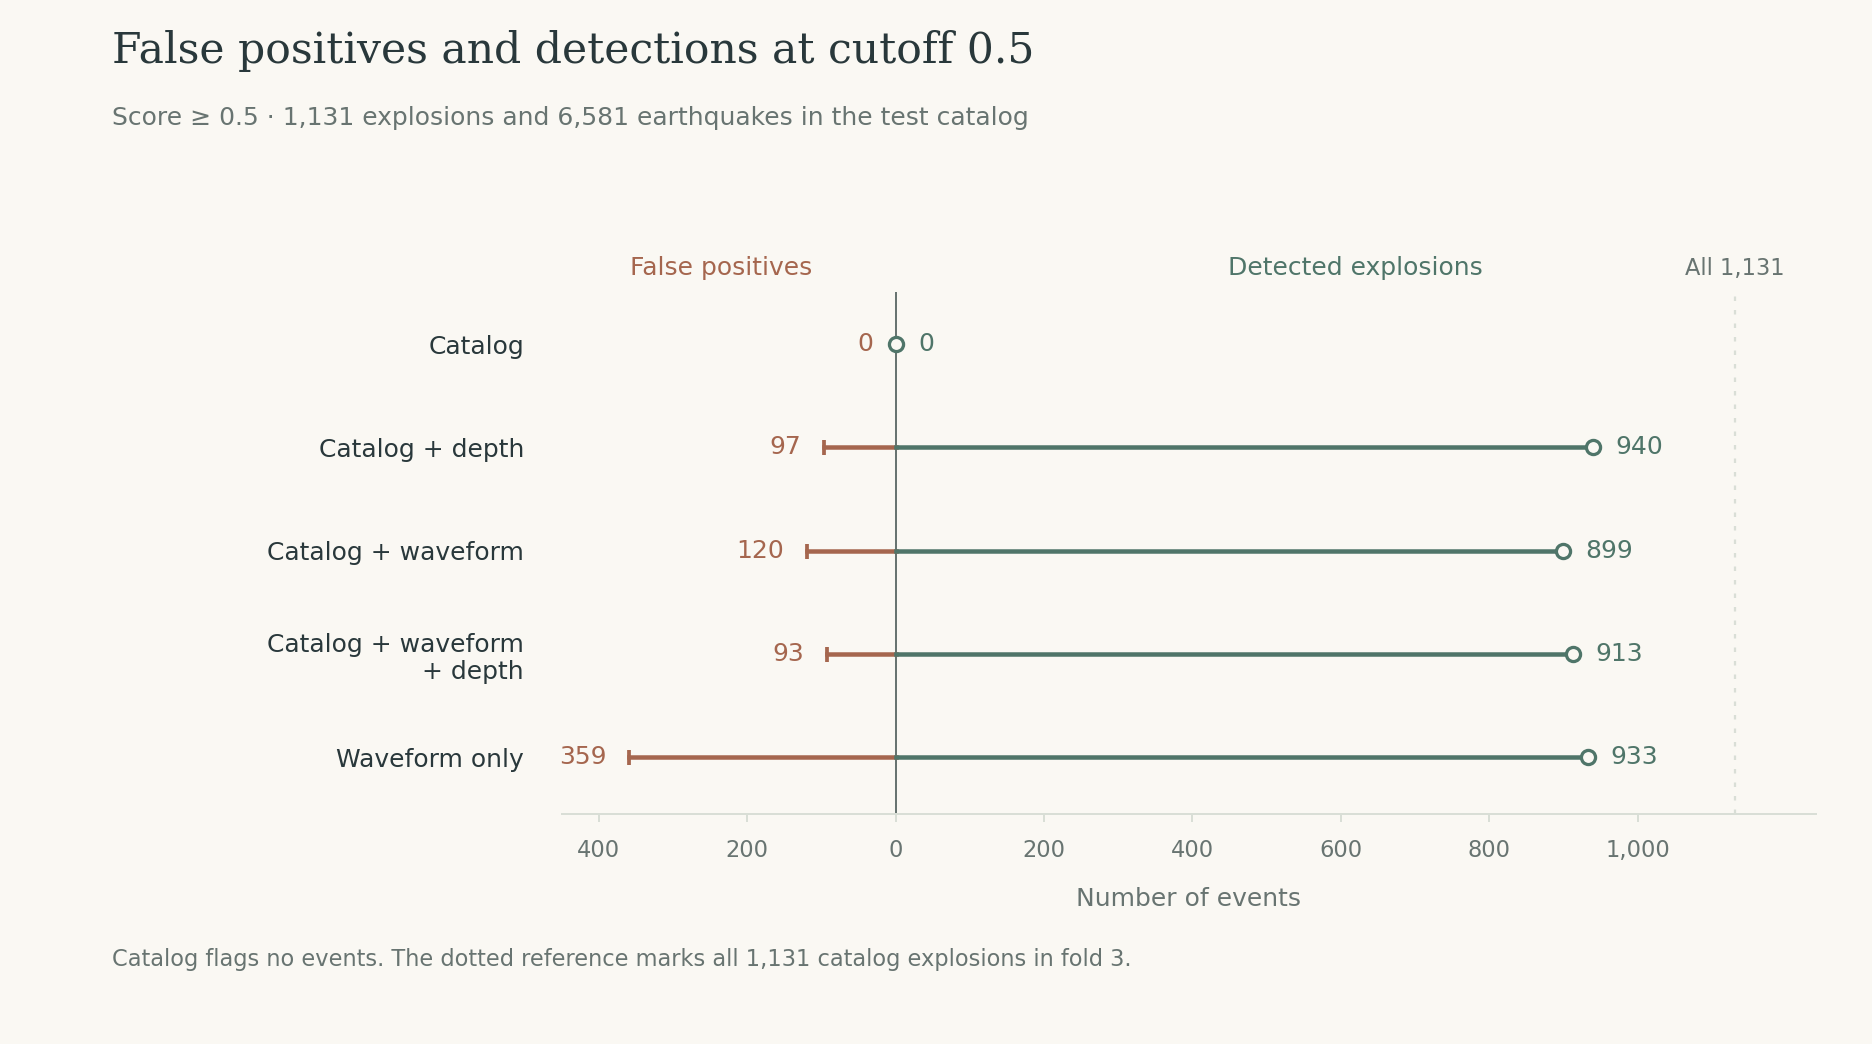

In [7]:
fig, ax = plt.subplots(figsize=(10.4, 5.8))
fig.subplots_adjust(left=0.30, right=0.97, bottom=0.22, top=0.72)
fig.text(0.06, 0.94, "False positives and detections at cutoff 0.5",
         family="DejaVu Serif", fontsize=17)
fig.text(0.06, 0.88, "Score ≥ 0.5 · 1,131 explosions and 6,581 earthquakes in the test catalog", color=MUTED)

for i, row in enumerate(results.itertuples()):
    y = len(results) - 1 - i
    ax.plot([-row.false_positive, 0], [y, y], color=CLAY, linewidth=1.8)
    ax.plot([0, row.true_positive], [y, y], color=SAGE, linewidth=1.8)
    ax.scatter(-row.false_positive, y, s=36, marker="|", color=CLAY, zorder=3)
    ax.scatter(row.true_positive, y, s=32, facecolor=PAPER, edgecolor=SAGE, linewidth=1.3, zorder=3)
    ax.annotate(f"{row.false_positive:,}", (-row.false_positive, y),
                xytext=(-9, 0), textcoords="offset points", ha="right", va="center", color=CLAY)
    ax.annotate(f"{row.true_positive:,}", (row.true_positive, y),
                xytext=(9, 0), textcoords="offset points", ha="left", va="center", color=SAGE)

ax.set_xlim(-450, 1240)
ax.set_ylim(-0.55, 4.5)
ax.set_yticks(range(4, -1, -1), ["Catalog", "Catalog + depth", "Catalog + waveform",
                               "Catalog + waveform\n+ depth", "Waveform only"])
ax.tick_params(axis="y", length=0, pad=15, labelsize=10)
ax.tick_params(axis="x", length=3, color=RULE, pad=7, labelsize=9)
ax.set_xticks([-400, -200, 0, 200, 400, 600, 800, 1000])
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{abs(x):,.0f}"))
ax.set_xlabel("Number of events", labelpad=10, fontsize=10)
ax.spines["left"].set_visible(False)
ax.axvline(0, color=MUTED, linewidth=0.8, zorder=0)
ax.axvline(int(y_test.sum()), color=RULE, linestyle=(0, (2, 4)), linewidth=0.9, zorder=0)
ax.text(-235, 4.67, "False positives", ha="center", color=CLAY, fontsize=10)
ax.text(620, 4.67, "Detected explosions", ha="center", color=SAGE, fontsize=10)
ax.text(1131, 4.67, "All 1,131", ha="center", color=MUTED, fontsize=9)
fig.text(0.06, 0.075, "Catalog flags no events. The dotted reference marks all 1,131 catalog explosions in fold 3.",
         fontsize=9, color=MUTED)
plt.show()


At cutoff 0.5, Catalog + depth has **27 more true positives and four more false positives in total** than Catalog + waveform + depth. The full model has higher AP, but AP covers many cutoffs; it does not tell us which model detects more explosions at 0.5.

- **Precision:** the fraction of flagged events that are catalog explosions.
- **Recall:** the fraction of catalog explosions detected.
- **F1:** a score that combines precision and recall; it is high only when both are high.
- **ROC AUC:** how well the scores rank explosions above earthquakes; higher is better.
- **Brier score:** the mean squared difference between the explosion score and the catalog label; lower is better.

Catalog flags no events, so its precision has a zero denominator and is undefined. The code records it as 0 using `zero_division=0`. Its recall and F1 are also 0.

The count columns are TN (correctly classified earthquakes), FP (false flags), FN (missed explosions) and TP (detected explosions).

We evaluated only one test fold and did not estimate variation across folds or uncertainty intervals. Any features, model settings or cutoff chosen using fold 3 need evaluation on independent test data.


In [8]:
summary = results[[
    "model", "average_precision", "roc_auc", "brier_score",
    "precision", "recall", "f1",
    "true_negative", "false_positive", "false_negative", "true_positive",
]].copy()
summary.columns = ["Feature set", "AP", "ROC AUC", "Brier", "Precision", "Recall", "F1", "TN", "FP", "FN", "TP"]
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


               Feature set     AP  ROC AUC  Brier  Precision  Recall     F1   TN  FP   FN  TP
                   Catalog 0.3728   0.8445 0.0979     0.0000  0.0000 0.0000 6581   0 1131   0
           Catalog + depth 0.8493   0.9576 0.0320     0.9065  0.8311 0.8672 6484  97  191 940
        Catalog + waveform 0.7934   0.9361 0.0405     0.8822  0.7949 0.8363 6461 120  232 899
Catalog + waveform + depth 0.8647   0.9652 0.0283     0.9076  0.8073 0.8545 6488  93  218 913
             Waveform only 0.7844   0.9403 0.0510     0.7221  0.8249 0.7701 6222 359  198 933
